# 第七組
# 組員: 數學系 碩二 陳宗毅

In [46]:
import os
import datetime
import math
import time
import IPython
import IPython.display
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models, optimizers, callbacks
from tensorflow.keras.layers import Input, Conv1D, BatchNormalization, Flatten, Dropout, Dense, Reshape
from tensorflow.keras.models import load_model
from sklearn.metrics import mean_squared_error, r2_score
from typing import Dict, Tuple, List

mpl.rcParams['figure.figsize'] = (8, 6)
mpl.rcParams['axes.grid'] = False

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## Load Data

In [3]:
# 儲存資料夾
BASE_DIR = '/content/drive/MyDrive/Final_project_DL'
os.makedirs(BASE_DIR, exist_ok=True)

# 下載並解壓到該資料夾
zip_path = tf.keras.utils.get_file(
    origin='https://storage.googleapis.com/tensorflow/tf-keras-datasets/jena_climate_2009_2016.csv.zip',
    fname='jena_climate_2009_2016.csv.zip',
    cache_dir=BASE_DIR,
    cache_subdir='',
    extract=True
)

# csv 路徑
csv_path = f"{zip_path}/jena_climate_2009_2016.csv"

print("ZIP path:", zip_path)
print("CSV path:", csv_path)

ZIP path: /content/drive/MyDrive/Final_project_DL/jena_climate_2009_2016_extracted
CSV path: /content/drive/MyDrive/Final_project_DL/jena_climate_2009_2016_extracted/jena_climate_2009_2016.csv


In [4]:
df = pd.read_csv(csv_path)
# Slice [start:stop:step], starting from index 5 take every 6th record.
df = df[5::6]

date_time = pd.to_datetime(df.pop('Date Time'), format='%d.%m.%Y %H:%M:%S')
df.head()

,p (mbar),T (degC),Tpot (K),Tdew (degC),rh (%),VPmax (mbar),VPact (mbar),VPdef (mbar),sh (g/kg),H2OC (mmol/mol),rho (g/m**3),wv (m/s),max. wv (m/s),wd (deg)
5,996.50,-8.05,265.38,-8.78,94.4,3.33,3.14,0.19,1.96,3.15,1307.86,0.21,0.63,192.7
11,996.62,-8.88,264.54,-9.77,93.2,3.12,2.90,0.21,1.81,2.91,1312.25,0.25,0.63,190.3
17,996.84,-8.81,264.59,-9.66,93.5,3.13,2.93,0.20,1.83,2.94,1312.18,0.18,0.63,167.2
23,996.99,-9.05,264.34,-10.02,92.6,3.07,2.85,0.23,1.78,2.85,1313.61,0.10,0.38,240.0
29,997.46,-9.63,263.72,-10.65,92.2,2.94,2.71,0.23,1.69,2.71,1317.19,0.40,0.88,157.0


## Data Cleaning

In [5]:
df.describe().transpose()

,count,mean,std,min,25%,50%,75%,max
p (mbar),70091.0,989.212842,8.358886,913.60,984.20,989.57,994.720,1015.29
T (degC),70091.0,9.450482,8.423384,-22.76,3.35,9.41,15.480,37.28
Tpot (K),70091.0,283.493086,8.504424,250.85,277.44,283.46,289.530,311.21
Tdew (degC),70091.0,4.956471,6.730081,-24.80,0.24,5.21,10.080,23.06
rh (%),70091.0,76.009788,16.474920,13.88,65.21,79.30,89.400,100.00
VPmax (mbar),70091.0,13.576576,7.739883,0.97,7.77,11.82,17.610,63.77
VPact (mbar),70091.0,9.533968,4.183658,0.81,6.22,8.86,12.360,28.25
VPdef (mbar),70091.0,4.042536,4.898549,0.00,0.87,2.19,5.300,46.01
sh (g/kg),70091.0,6.022560,2.655812,0.51,3.92,5.59,7.800,18.07
H2OC (mmol/mol),70091.0,9.640437,4.234862,0.81,6.29,8.96,12.490,28.74


In [6]:
wv = df['wv (m/s)']
bad_wv = wv == -9999.0
wv[bad_wv] = 0.0

max_wv = df['max. wv (m/s)']
bad_max_wv = max_wv == -9999.0
max_wv[bad_max_wv] = 0.0

# The above inplace edits are reflected in the DataFrame.
df.describe().transpose()

,count,mean,std,min,25%,50%,75%,max
p (mbar),70091.0,989.212842,8.358886,913.60,984.20,989.57,994.720,1015.29
T (degC),70091.0,9.450482,8.423384,-22.76,3.35,9.41,15.480,37.28
Tpot (K),70091.0,283.493086,8.504424,250.85,277.44,283.46,289.530,311.21
Tdew (degC),70091.0,4.956471,6.730081,-24.80,0.24,5.21,10.080,23.06
rh (%),70091.0,76.009788,16.474920,13.88,65.21,79.30,89.400,100.00
VPmax (mbar),70091.0,13.576576,7.739883,0.97,7.77,11.82,17.610,63.77
VPact (mbar),70091.0,9.533968,4.183658,0.81,6.22,8.86,12.360,28.25
VPdef (mbar),70091.0,4.042536,4.898549,0.00,0.87,2.19,5.300,46.01
sh (g/kg),70091.0,6.022560,2.655812,0.51,3.92,5.59,7.800,18.07
H2OC (mmol/mol),70091.0,9.640437,4.234862,0.81,6.29,8.96,12.490,28.74


In [7]:
timestamp_s = date_time.map(pd.Timestamp.timestamp)
day = 24*60*60
year = (365.2425)*day

df['Day sin'] = np.sin(timestamp_s * (2 * np.pi / day))
df['Day cos'] = np.cos(timestamp_s * (2 * np.pi / day))
df['Year sin'] = np.sin(timestamp_s * (2 * np.pi / year))
df['Year cos'] = np.cos(timestamp_s * (2 * np.pi / year))

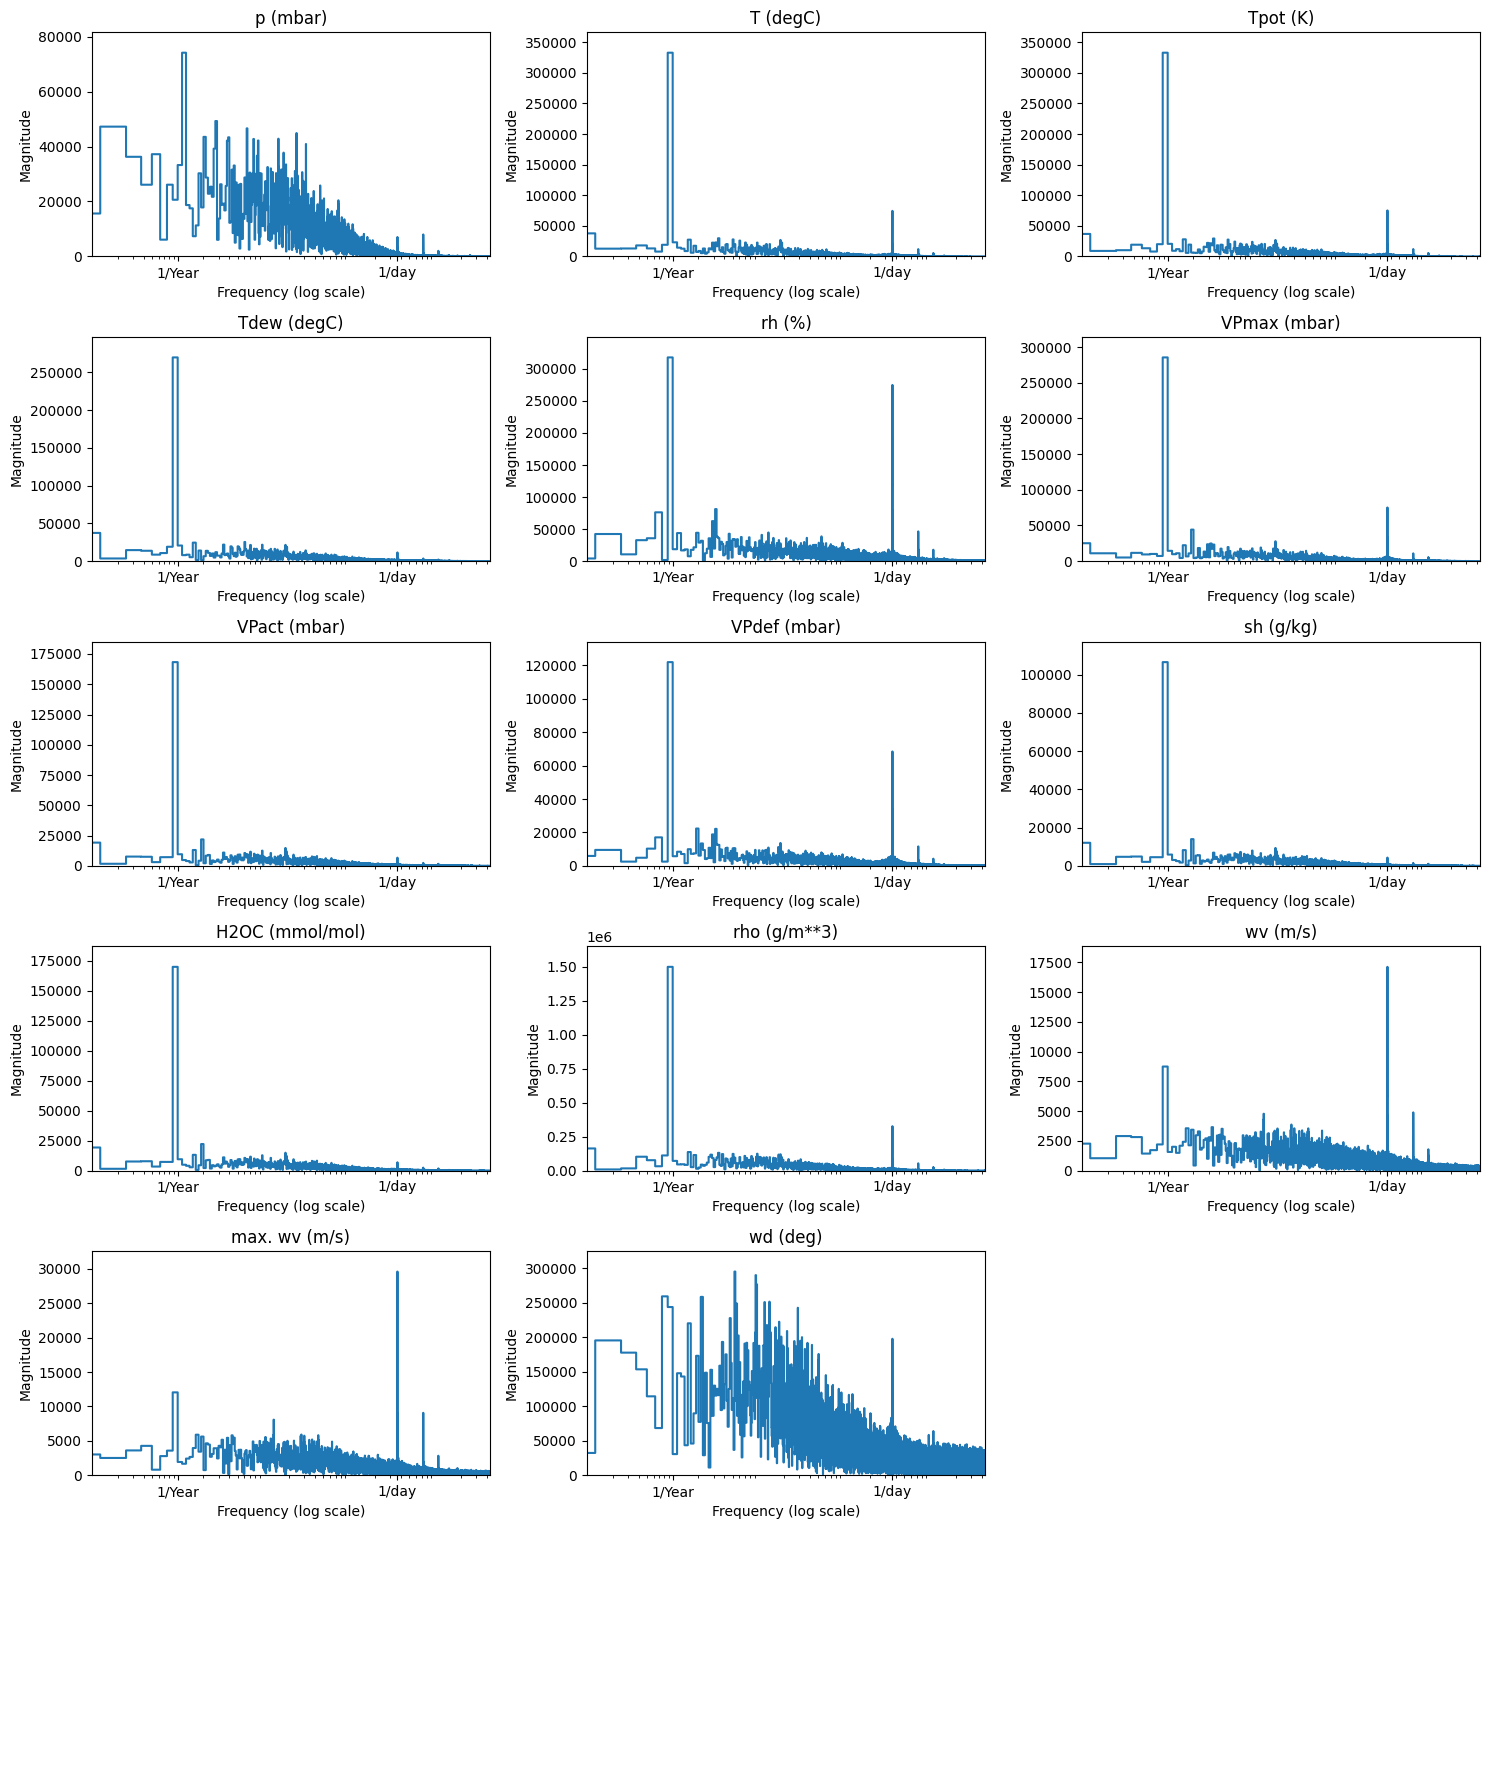

In [8]:

n_samples_h = len(df)
hours_per_year = 24*365.2524
years_per_dataset = n_samples_h / hours_per_year

columns = df.columns
n_cols = 3
n_rows = int(np.ceil(len(columns)/n_cols))

top_k = 3  # 前幾高峰

# 儲存 top_k periods 的字典
top_periods_dict = {col: [] for col in columns}

fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, n_rows*3))
axes = axes.flatten()

for i, col in enumerate(columns[:14]):
    series = df[col].values
    fft = tf.signal.rfft(series - np.mean(series)).numpy()
    mag = np.abs(fft)
    f_per_dataset = np.arange(len(fft))
    f_per_year = f_per_dataset / years_per_dataset

    axes[i].step(f_per_year, mag)
    axes[i].set_xscale('log')
    axes[i].set_xlim([0.1, max(f_per_year)])
    axes[i].set_ylim(0, np.max(mag)*1.1)
    axes[i].set_xticks([1, 365.2524])
    axes[i].set_xticklabels(['1/Year', '1/day'])
    axes[i].set_xlabel('Frequency (log scale)')
    axes[i].set_ylabel('Magnitude')
    axes[i].set_title(col)

    # 找 top_k peak indices（排除直流分量 idx=0）
    peak_indices = np.argsort(mag[1:])[::-1][:top_k] + 1  # +1 因為跳過 idx=0
    for idx in peak_indices:
        freq = f_per_year[idx]
        period_hours = hours_per_year / freq
        top_periods_dict[col].append(period_hours)


# 隱藏多餘軸
for j in range(i+1, len(axes)):
    axes[j].axis('off')

plt.tight_layout()
plt.show()



In [9]:
# 轉成 DataFrame
top_periods_df = pd.DataFrame.from_dict(top_periods_dict, orient='index',
                                       columns=[f'top{i+1}' for i in range(top_k)])
top_periods_df.reset_index(inplace=True)
top_periods_df.rename(columns={'index': 'column_name'}, inplace=True)

# 查看結果
print(top_periods_df)

        column_name         top1          top2          top3
0          p (mbar)  7009.100000   3047.434783  35045.500000
1          T (degC)  8761.375000     23.995549     24.003767
2          Tpot (K)  8761.375000     23.995549     24.003767
3       Tdew (degC)  8761.375000  70091.000000   1430.428571
4            rh (%)  8761.375000     23.995549     24.003767
5      VPmax (mbar)  8761.375000     23.995549     24.003767
6      VPact (mbar)  8761.375000   4380.687500  70091.000000
7      VPdef (mbar)  8761.375000     23.995549     24.003767
8         sh (g/kg)  8761.375000   4380.687500  70091.000000
9   H2OC (mmol/mol)  8761.375000   4380.687500  70091.000000
10     rho (g/m**3)  8761.375000     23.995549     24.003767
11         wv (m/s)    23.995549     24.003767   8761.375000
12    max. wv (m/s)    23.995549     24.003767     24.011990
13         wd (deg)  1630.023256    934.546667    910.272727
14          Day sin          NaN           NaN           NaN
15          Day cos     

## Split the data

In [10]:
column_indices = {name: i for i, name in enumerate(df.columns)}

n = len(df)
train_df = df[0:int(n*0.7)]
val_df = df[int(n*0.7):int(n*0.9)]
test_df = df[int(n*0.9):]

num_features = df.shape[1]

print(train_df.shape)
print(val_df.shape)
print(test_df.shape)

(49063, 18)
(14018, 18)
(7010, 18)


In [11]:
train_mean = train_df.mean()
train_std = train_df.std()

train_df = (train_df - train_mean) / train_std
val_df = (val_df - train_mean) / train_std
test_df = (test_df - train_mean) / train_std
df_std = (df - train_mean) / train_std
df_std = df_std.melt(var_name='Column', value_name='Normalized')

## Data windowing Algorithm

In [12]:
class WindowGenerator:
    def __init__(
        self,
        input_width,
        label_width,
        shift,
        train_df,
        val_df,
        test_df,
        input_columns,
        label_columns,
        batch_size=128
    ):
        self.train_df = train_df
        self.val_df = val_df
        self.test_df = test_df

        self.input_width = int(input_width)
        self.label_width = int(label_width)
        self.shift = int(shift)

        self.total_window_size = self.input_width + self.shift

        self.input_slice = slice(0, self.input_width)
        self.label_start = self.total_window_size - self.label_width
        self.labels_slice = slice(self.label_start, None)

        self.input_columns = input_columns
        self.label_columns = label_columns

        self.column_indices = {
            name: i for i, name in enumerate(train_df.columns)
        }

        self.batch_size = batch_size

        # ---- dataset cache ----
        self._train_ds = None
        self._val_ds = None
        self._test_ds = None

    def split_window(self, features):
        inputs = features[:, self.input_slice, :]
        labels = features[:, self.labels_slice, :]

        inputs = tf.stack(
            [inputs[:, :, self.column_indices[self.train_df.columns[i]]]
             for i in self.input_columns],
            axis=-1
        )

        labels = tf.stack(
            [labels[:, :, self.column_indices[self.train_df.columns[i]]]
             for i in self.label_columns],
            axis=-1
        )

        return inputs, labels

    def make_dataset(self, data):
        data = np.array(data, dtype=np.float32)

        ds = tf.keras.preprocessing.timeseries_dataset_from_array(
            data=data,
            targets=None,
            sequence_length=self.total_window_size,
            sequence_stride=1,
            shuffle=True,
            batch_size=self.batch_size,
        )

        ds = ds.map(self.split_window, num_parallel_calls=tf.data.AUTOTUNE)
        return ds.cache().prefetch(tf.data.AUTOTUNE)

    def train(self):
        if self._train_ds is None:
            self._train_ds = self.make_dataset(self.train_df)
        return self._train_ds

    def val(self):
        if self._val_ds is None:
            self._val_ds = self.make_dataset(self.val_df)
        return self._val_ds

    def test(self):
        if self._test_ds is None:
            self._test_ds = self.make_dataset(self.test_df)
        return self._test_ds

In [13]:
def build_lightweight_baseline(input_width, num_input_cols,
                               label_width, num_label_cols):

    inputs = tf.keras.layers.Input(shape=(input_width, num_input_cols))

    x = tf.keras.layers.Conv1D(
        filters=64,
        kernel_size=3,
        padding="causal",
        activation="relu"
    )(inputs)

    x = tf.keras.layers.Conv1D(
        filters=64,
        kernel_size=3,
        padding="causal",
        activation="relu"
    )(x)

    x = tf.keras.layers.GlobalAveragePooling1D()(x)

    x = tf.keras.layers.Dense(128, activation="relu")(x)

    outputs = tf.keras.layers.Dense(
        label_width * num_label_cols
    )(x)

    outputs = tf.keras.layers.Reshape(
        (label_width, num_label_cols)
    )(outputs)

    model = tf.keras.Model(inputs, outputs)
    model.compile(
        optimizer=tf.keras.optimizers.Adam(1e-3),
        loss="mae",
        metrics=["mae"]
    )
    return model




def evaluate_candidates_with_offset(
    train_df, val_df, test_df,
    input_candidates=[24,48,72,168],
    label_candidates=[6,12,18,24],
    offset_steps=[0,2,4,6],
    input_cols=None,
    label_cols=None,
    batch_size=128,
    epochs=5,
    tol=0.05
):
    if input_cols is None:
        input_cols = list(range(train_df.shape[1]))
    if label_cols is None:
        label_cols = list(range(15))

    records = []

    for iw in input_candidates:
        for lw in label_candidates:
            for k in offset_steps:
                shift = iw - k
                if shift <= 0:
                    continue

                if min(len(train_df), len(val_df)) < iw + shift:
                    continue

                wg = WindowGenerator(
                    input_width=iw,
                    label_width=lw,
                    shift=shift,
                    train_df=train_df,
                    val_df=val_df,
                    test_df=test_df,
                    input_columns=input_cols,
                    label_columns=label_cols,
                    batch_size=batch_size
                )

                model = build_lightweight_baseline(
                    iw, len(input_cols),
                    lw, len(label_cols)
                )

                t0 = time.time()
                hist = model.fit(
                    wg.train(),
                    validation_data=wg.val(),
                    epochs=epochs,
                    verbose=0
                )

                records.append({
                    "input_width": iw,
                    "label_width": lw,
                    "shift": shift,
                    "offset": k,
                    "val_mae": hist.history["val_mae"][-1],
                    "time_sec": time.time() - t0
                })

                tf.keras.backend.clear_session()

    df = pd.DataFrame(records)

    best_val = df.val_mae.min()
    candidates = df[df.val_mae <= best_val * (1 + tol)]

    chosen = candidates.sort_values(
        ["time_sec", "val_mae"]
    ).iloc[0].to_dict()

    return df.sort_values("val_mae"), chosen


In [14]:
input_cols = list(range(0,18))
label_cols = list(range(0,14))

train_df2 = train_df.iloc[:7000]
val_df2   = val_df.iloc[:2000]
test_df2  = test_df.iloc[:1000]

results_df, best_cfg = evaluate_candidates_with_offset(
    train_df2, val_df2, test_df2,
    input_candidates=[24,48,72,168],
    label_candidates=[6,12,18,24],
    offset_steps=[0,3,6,12],
    input_cols=list(range(18)),
    label_cols=list(range(14)),
    epochs=5
)

print(results_df)
print("Chosen config:", best_cfg)

    input_width  label_width  shift  offset   val_mae  time_sec
15           24           24     12      12  0.334657  6.910448
11           24           18     12      12  0.347565  6.919790
7            24           12     12      12  0.376277  6.687824
14           24           24     18       6  0.381767  5.641949
3            24            6     12      12  0.382618  7.367896
..          ...          ...    ...     ...       ...       ...
49          168            6    165       3  0.709440  6.270092
37           72           12     69       3  0.714800  6.466802
56          168           18    168       0  0.726448  6.040454
55          168           12    156      12  0.730844  7.742682
42           72           18     66       6  0.741701  5.858441

[64 rows x 6 columns]
Chosen config: {'input_width': 24.0, 'label_width': 24.0, 'shift': 12.0, 'offset': 12.0, 'val_mae': 0.3346574604511261, 'time_sec': 6.910447835922241}


## Hyperparams

In [15]:
# ====== 參數（根據 chosen config） ======
INPUT_WIDTH = 24
LABEL_WIDTH = 24
SHIFT = 12
INPUT_COLS = list(range(0,18))
LABEL_COLS = list(range(0,14))

BATCH_SIZE = 64

MODELS_DIR = os.path.join(BASE_DIR, "Models")
os.makedirs(MODELS_DIR, exist_ok=True)

In [16]:
# ====== 建立 WindowGenerator instance（使用你提供的 class） ======
wg = WindowGenerator(
    input_width=INPUT_WIDTH,
    label_width=LABEL_WIDTH,
    shift=SHIFT,
    train_df=train_df,
    val_df=val_df,
    test_df=test_df,
    input_columns=INPUT_COLS,
    label_columns=LABEL_COLS,
    batch_size=BATCH_SIZE
)

In [17]:
train_ds = wg.train()
val_ds = wg.val()
test_ds = wg.test()

In [18]:
# reshape dataset
def flatten_ds(ds):
    return ds.map(lambda x, y: (tf.reshape(x, [tf.shape(x)[0], -1]), y))

train_ds_flat = flatten_ds(train_ds)
val_ds_flat = flatten_ds(val_ds)
test_ds_flat = flatten_ds(test_ds)

## Model

In [19]:
# RMSE metric for Keras
def root_mean_squared_error(y_true, y_pred):
    return tf.sqrt(tf.reduce_mean(tf.square(y_pred - y_true)))

def build_dense_model_flat(input_width, num_input_cols, label_width, num_label_cols):
    inputs = tf.keras.layers.Input(shape=(input_width * num_input_cols,))
    x = tf.keras.layers.Dense(256, activation='relu')(inputs)
    x = tf.keras.layers.Dense(128, activation='relu')(x)
    x = tf.keras.layers.Dense(128, activation='relu')(x)
    outputs = tf.keras.layers.Dense(label_width * num_label_cols)(x)
    outputs = tf.keras.layers.Reshape((label_width, num_label_cols))(outputs)
    model = tf.keras.Model(inputs=inputs, outputs=outputs)
    model.compile(
        optimizer=tf.keras.optimizers.Adam(1e-3),
        loss='mse',
        metrics=[root_mean_squared_error]
    )
    return model





def build_cnn_model(
    input_width,
    num_input_cols,
    label_width,
    num_label_cols,
    dropout=0.1
):
    inputs = Input(shape=(input_width, num_input_cols))

    # ---- Block 1 (local patterns) ----
    x = Conv1D(
        64, 3,
        padding="causal",
        activation="relu"
    )(inputs)
    x = BatchNormalization()(x)

    # ---- Block 2 (mid-range patterns) ----
    x = Conv1D(
        64, 3,
        padding="causal",
        dilation_rate=2,
        activation="relu"
    )(x)
    x = BatchNormalization()(x)

    # ---- Block 3 (long-range patterns) ----
    x = Conv1D(
        64, 3,
        padding="causal",
        dilation_rate=4,
        activation="relu"
    )(x)
    x = BatchNormalization()(x)

    # ---- Temporal aggregation ----
    x = tf.keras.layers.GlobalAveragePooling1D()(x)
    x = Dropout(dropout)(x)

    # ---- Dense head ----
    x = Dense(128, activation="relu")(x)
    x = Dropout(dropout)(x)

    outputs = Dense(label_width * num_label_cols)(x)
    outputs = Reshape((label_width, num_label_cols))(outputs)

    model = tf.keras.Model(inputs, outputs)
    model.compile(
        optimizer=tf.keras.optimizers.Adam(3e-4),
        loss="mse",
        metrics=[tf.keras.metrics.RootMeanSquaredError()]
    )
    return model





def build_lstm_model(input_width, num_input_cols, label_width, num_label_cols, dropout=0.1):
    inputs = tf.keras.layers.Input(shape=(input_width, num_input_cols))

    x = tf.keras.layers.LSTM(
        128,
        return_sequences=True,
        recurrent_dropout=0.1
    )(inputs)

    x = tf.keras.layers.LSTM(
        64,
        recurrent_dropout=0.1
    )(x)

    x = tf.keras.layers.Dense(128, activation='relu')(x)
    x = tf.keras.layers.Dropout(dropout)(x)

    outputs = tf.keras.layers.Dense(label_width * num_label_cols)(x)
    outputs = tf.keras.layers.Reshape((label_width, num_label_cols))(outputs)

    model = tf.keras.Model(inputs, outputs)
    model.compile(
        optimizer=tf.keras.optimizers.Adam(1e-3),
        loss='mse',
        metrics=[root_mean_squared_error]
    )
    return model



## training

In [20]:
def train_model(model, train_ds, val_ds, epochs=30):
    history = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=epochs,
        verbose=1
    )
    return history


In [21]:
def evaluate_model(model, ds):
    y_true_list = []
    y_pred_list = []

    for x, y in ds:
        y_pred = model.predict(x)
        y_true_list.append(y.numpy())
        y_pred_list.append(y_pred)

    y_true = np.concatenate(y_true_list, axis=0)
    y_pred = np.concatenate(y_pred_list, axis=0)

    rmse = np.sqrt(mean_squared_error(y_true.reshape(-1, y_true.shape[-1]),
                                      y_pred.reshape(-1, y_pred.shape[-1])))
    r2 = r2_score(y_true.reshape(-1, y_true.shape[-1]),
                  y_pred.reshape(-1, y_pred.shape[-1]),
                  multioutput='uniform_average')
    return rmse, r2


### Dense

In [154]:
# ---------- 1) Dense ----------
dense_model = build_dense_model_flat(INPUT_WIDTH, len(INPUT_COLS), LABEL_WIDTH, len(LABEL_COLS))
dense_model.summary()

Model: "functional_29"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_29 (InputLayer)     │ (None, 432)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_97 (Dense)                │ (None, 256)            │       110,848 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_98 (Dense)                │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_99 (Dense)                │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_100 (Dense)               │ (None, 336)            │        43,344 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape_29 (Reshape)            │ (None, 24, 14)         │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 203,600 (795.31 KB)

 Trainable params: 203,600 (795.31 KB)

 Non-trainable params: 0 (0.00 B)

In [155]:
dense_history = train_model(dense_model, train_ds_flat, val_ds_flat, epochs=50)

Epoch 1/50
767/767 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - loss: 0.2865 - root_mean_squared_error: 0.5097 - val_loss: 0.1511 - val_root_mean_squared_error: 0.3883
Epoch 2/50
767/767 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.1347 - root_mean_squared_error: 0.3667 - val_loss: 0.1366 - val_root_mean_squared_error: 0.3692
Epoch 3/50
767/767 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.1204 - root_mean_squared_error: 0.3466 - val_loss: 0.1267 - val_root_mean_squared_error: 0.3555
Epoch 4/50
767/767 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 0.1133 - root_mean_squared_error: 0.3363 - val_loss: 0.1238 - val_root_mean_squared_error: 0.3514
Epoch 5/50
767/767 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.1095 - root_mean_squared_error: 0.3306 - val_loss: 0.1217 - val_root_mean_squared_error: 0.3484
Epoch 6/50
767/767 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.1069 - root_mean_squared_error: 0.3266 - val_loss: 0.1213 - val_root_mean_squared_error: 0.3479
Epoch 7/50
767/767 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step 

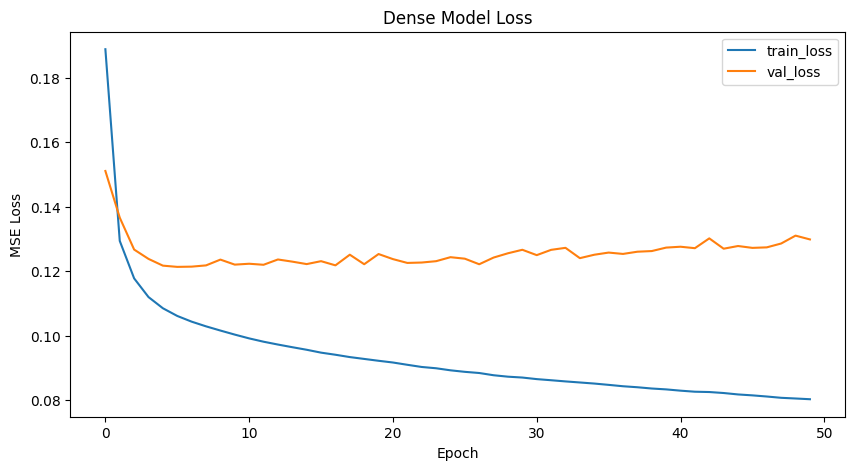

In [156]:
# --- Plot loss / val_loss ---
plt.figure(figsize=(10,5))
plt.plot(dense_history.history['loss'], label='train_loss')
plt.plot(dense_history.history['val_loss'], label='val_loss')
plt.title('Dense Model Loss')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.legend()
plt.show()

In [191]:
# --- Flatten test dataset ---
test_ds_flat = test_ds.map(lambda x, y: (tf.reshape(x, [tf.shape(x)[0], -1]), y))

# --- Evaluate on test dataset ---
y_true_list = []
y_pred_list = []

for x, y in test_ds_flat:
    y_pred = dense_model.predict(x)
    y_true_list.append(y.numpy())
    y_pred_list.append(y_pred)

y_true = np.concatenate(y_true_list, axis=0)
y_pred = np.concatenate(y_pred_list, axis=0)

rmse = np.sqrt(mean_squared_error(
    y_true.reshape(-1, y_true.shape[-1]),
    y_pred.reshape(-1, y_pred.shape[-1])
))
r2 = r2_score(
    y_true.reshape(-1, y_true.shape[-1]),
    y_pred.reshape(-1, y_pred.shape[-1]),
    multioutput='uniform_average'
)

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step
2/2 ━━━━━━━━

In [158]:
print(f"Dense Test RMSE: {rmse:.4f}, R2: {r2:.4f}")

Dense Test RMSE: 0.3334, R2: 0.8793


In [159]:
# --- 4) Save model ---
model_path = os.path.join(MODELS_DIR, "dense_model.keras")
dense_model.save(model_path)
print(f"Dense model saved to: {model_path}")

Dense model saved to: /content/drive/MyDrive/Final_project_DL/Models/dense_model.keras


### CNN

In [26]:
# CNN model
cnn_model = build_cnn_model(INPUT_WIDTH, len(INPUT_COLS), LABEL_WIDTH, len(LABEL_COLS))
cnn_model.summary()

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 24, 18)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_6 (Conv1D)               │ (None, 24, 64)         │         3,520 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 24, 64)         │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_7 (Conv1D)               │ (None, 24, 64)         │        12,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 24, 64)         │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_8 (Conv1D)               │ (None, 24, 64)         │        12,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 24, 64)         │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d_2      │ (None, 64)             │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 336)            │        43,344 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape_2 (Reshape)             │ (None, 24, 14)         │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 80,656 (315.06 KB)

 Trainable params: 80,272 (313.56 KB)

 Non-trainable params: 384 (1.50 KB)

In [27]:
cnn_history = train_model(cnn_model, train_ds, val_ds, epochs=50)

Epoch 1/50
767/767 ━━━━━━━━━━━━━━━━━━━━ 13s 9ms/step - loss: 0.5166 - root_mean_squared_error: 0.7122 - val_loss: 0.2273 - val_root_mean_squared_error: 0.4768
Epoch 2/50
767/767 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 0.2436 - root_mean_squared_error: 0.4936 - val_loss: 0.2028 - val_root_mean_squared_error: 0.4504
Epoch 3/50
767/767 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 0.2168 - root_mean_squared_error: 0.4656 - val_loss: 0.1901 - val_root_mean_squared_error: 0.4360
Epoch 4/50
767/767 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - loss: 0.2032 - root_mean_squared_error: 0.4507 - val_loss: 0.1806 - val_root_mean_squared_error: 0.4250
Epoch 5/50
767/767 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - loss: 0.1946 - root_mean_squared_error: 0.4411 - val_loss: 0.1765 - val_root_mean_squared_error: 0.4201
Epoch 6/50
767/767 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - loss: 0.1881 - root_mean_squared_error: 0.4337 - val_loss: 0.1691 - val_root_mean_squared_error: 0.4112
Epoch 7/50
767/767 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step

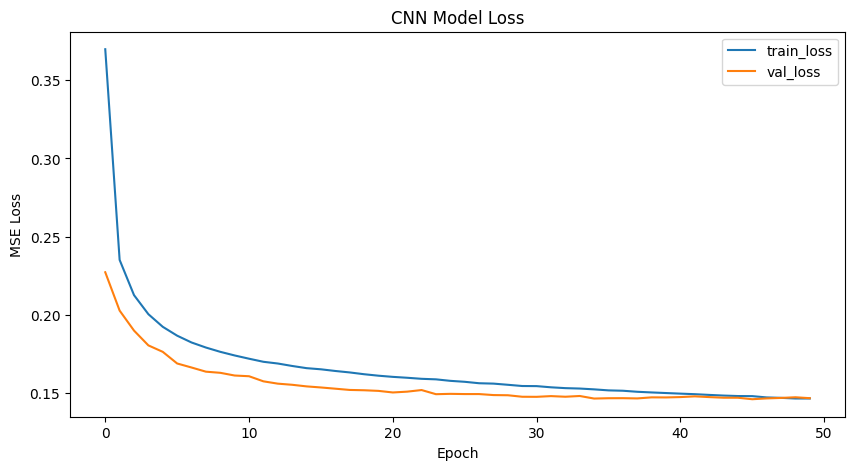

In [28]:
# --- Plot loss / val_loss ---
plt.figure(figsize=(10,5))
plt.plot(cnn_history.history['loss'], label='train_loss')
plt.plot(cnn_history.history['val_loss'], label='val_loss')
plt.title('CNN Model Loss')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.legend()
plt.show()

In [29]:
y_true_list = []
y_pred_list = []

for x, y in test_ds:
    # CNN 直接用原始 shape
    y_pred = cnn_model.predict(x)

    y_true_list.append(y.numpy())
    y_pred_list.append(y_pred)

# 合併所有 batch
y_true = np.concatenate(y_true_list, axis=0)
y_pred = np.concatenate(y_pred_list, axis=0)

# 計算 RMSE
rmse = np.sqrt(np.mean((y_true - y_pred)**2))


# 計算 R2
r2 = r2_score(
    y_true.reshape(-1, y_true.shape[-1]),
    y_pred.reshape(-1, y_pred.shape[-1]),
    multioutput='uniform_average'
)


2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step 
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
2/2 ━━━━━━━

In [30]:
print(f"CNN Test RMSE: {rmse:.4f}, R2: {r2:.4f}")

CNN Test RMSE: 0.3612, R2: 0.8581


In [31]:
# --- 4) Save model ---
model_path = os.path.join(MODELS_DIR, "cnn_model.keras")
cnn_model.save(model_path)
print(f"CNN model saved to: {model_path}")

CNN model saved to: /content/drive/MyDrive/Final_project_DL/Models/cnn_model.keras


### RNN

In [32]:
# RNN model
rnn_model = build_lstm_model(INPUT_WIDTH, len(INPUT_COLS), LABEL_WIDTH, len(LABEL_COLS))
rnn_model.summary()

Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 24, 18)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 24, 128)        │        75,264 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 64)             │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 336)            │        43,344 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape_3 (Reshape)             │ (None, 24, 14)         │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 176,336 (688.81 KB)

 Trainable params: 176,336 (688.81 KB)

 Non-trainable params: 0 (0.00 B)

In [33]:
rnn_history = train_model(rnn_model, train_ds, val_ds, epochs=30)

Epoch 1/30
767/767 ━━━━━━━━━━━━━━━━━━━━ 119s 144ms/step - loss: 0.3368 - root_mean_squared_error: 0.5597 - val_loss: 0.1673 - val_root_mean_squared_error: 0.4087
Epoch 2/30
767/767 ━━━━━━━━━━━━━━━━━━━━ 110s 143ms/step - loss: 0.1693 - root_mean_squared_error: 0.4111 - val_loss: 0.1547 - val_root_mean_squared_error: 0.3930
Epoch 3/30
767/767 ━━━━━━━━━━━━━━━━━━━━ 111s 145ms/step - loss: 0.1566 - root_mean_squared_error: 0.3954 - val_loss: 0.1474 - val_root_mean_squared_error: 0.3837
Epoch 4/30
767/767 ━━━━━━━━━━━━━━━━━━━━ 111s 145ms/step - loss: 0.1501 - root_mean_squared_error: 0.3871 - val_loss: 0.1440 - val_root_mean_squared_error: 0.3792
Epoch 5/30
767/767 ━━━━━━━━━━━━━━━━━━━━ 110s 143ms/step - loss: 0.1457 - root_mean_squared_error: 0.3815 - val_loss: 0.1445 - val_root_mean_squared_error: 0.3798
Epoch 6/30
767/767 ━━━━━━━━━━━━━━━━━━━━ 111s 145ms/step - loss: 0.1423 - root_mean_squared_error: 0.3769 - val_loss: 0.1407 - val_root_mean_squared_error: 0.3748
Epoch 7/30
767/767 ━━━━━━━━━

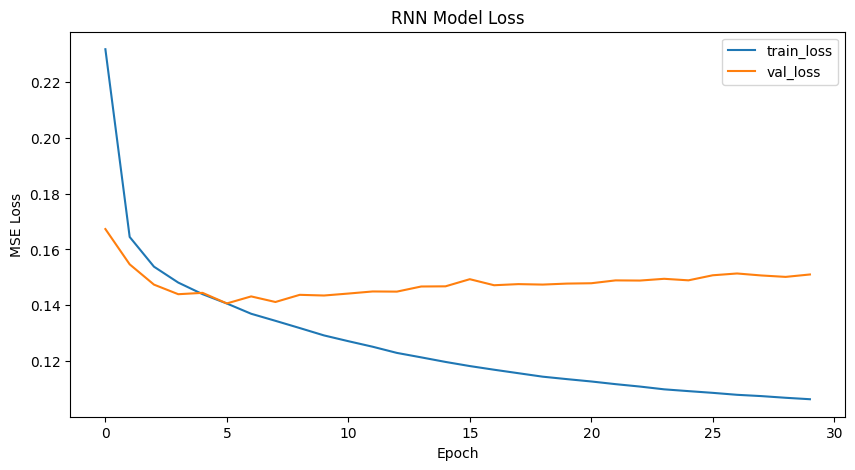

In [34]:
# --- Plot loss / val_loss ---
plt.figure(figsize=(10,5))
plt.plot(rnn_history.history['loss'], label='train_loss')
plt.plot(rnn_history.history['val_loss'], label='val_loss')
plt.title('RNN Model Loss')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.legend()
plt.show()

In [36]:
y_true_list = []
y_pred_list = []

for x, y in test_ds:
    # CNN 直接用原始 shape
    y_pred = rnn_model.predict(x)

    y_true_list.append(y.numpy())
    y_pred_list.append(y_pred)

# 合併所有 batch
y_true = np.concatenate(y_true_list, axis=0)
y_pred = np.concatenate(y_pred_list, axis=0)

# 計算 RMSE
rmse = np.sqrt(np.mean((y_true - y_pred)**2))


# 計算 R2
r2 = r2_score(
    y_true.reshape(-1, y_true.shape[-1]),
    y_pred.reshape(-1, y_pred.shape[-1]),
    multioutput='uniform_average'
)


2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 42ms/step 
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
2/2 ━━━━━━━

In [37]:
print(f"RNN Test RMSE: {rmse:.4f}, R2: {r2:.4f}")

RNN Test RMSE: 0.3646, R2: 0.8560


In [35]:
# --- Save model ---
model_path = os.path.join(MODELS_DIR, "rnn_model.keras")
rnn_model.save(model_path)
print(f"RNN model saved to: {model_path}")

RNN model saved to: /content/drive/MyDrive/Final_project_DL/Models/rnn_model.keras


## Forcasting Result

In [54]:
# ====== 輔助：載入模型（自動尋找 dense/cnn/rnn） ======
def load_three_models(models_dir: str) -> Dict[str, tf.keras.Model]:
    files = [f for f in os.listdir(models_dir) if f.endswith('.keras') or f.endswith('.h5')]
    files_lower = [f.lower() for f in files]
    chosen = {}
    # 嘗試找含關鍵字的檔名
    for name in ['dense', 'cnn', 'rnn', 'lstm']:
        for f, fl in zip(files, files_lower):
            if name in fl and name not in chosen:
                chosen[name] = os.path.join(models_dir, f)
    # 如果沒找到某些，填補前面幾個檔案
    if len(chosen) < 3:
        for f in files:
            if f not in chosen.values():
                # give generic keys until we have 3
                key = f.split('.')[0]
                if key not in chosen:
                    chosen[key] = os.path.join(models_dir, f)
            if len(chosen) >= 3:
                break
    # Load models and normalize keys to 'dense','cnn','rnn' if possible
    models = {}
    for k, path in chosen.items():
        try:
            m = load_model(path, compile=False)  # compile=False faster for loading
            models[k] = m
            print(f"Loaded model: {k} <- {path}")
        except Exception as e:
            print(f"Failed to load {path}: {e}")
    return models

# ====== 輔助：從 test_df 舉取一個 window 的 inputs/labels ======
def get_window_from_df(df, wg, start_idx: int) -> Tuple[np.ndarray, np.ndarray, np.ndarray]:
    """
    返回 (inputs, labels, time_index_array)
    - inputs: shape (input_width, num_input_cols)
    - labels: shape (label_width, num_label_cols)
    - time_index_array: array of length total_window_size (relative or datetime)
    """
    total = wg.total_window_size
    if start_idx < 0 or start_idx + total > len(df):
        raise ValueError("start_idx out of range")
    arr = df.values.astype(np.float32)
    window = arr[start_idx:start_idx + total, :]
    # pick columns by index lists
    inputs = window[wg.input_slice, :][:, wg.input_columns]
    labels = window[wg.labels_slice, :][:, wg.label_columns]
    # time index: if df.index is datetime-like, extract that slice; else numeric range
    try:
        time_idx = df.index[start_idx:start_idx + total]
    except Exception:
        time_idx = np.arange(start_idx, start_idx + total)
    return inputs, labels, time_idx

# ====== 輔助：調整 inputs 以符合不同 model 的 input_shape ======
def prepare_input_for_model(model: tf.keras.Model, inputs: np.ndarray) -> np.ndarray:
    """
    model: keras model
    inputs: shape (input_width, num_input_cols)
    returns: np array shaped (1, ...) ready to feed model.predict
    Handles 2D (flatten) vs 3D (timesteps, features) inputs.
    """
    inp_shape = model.input_shape  # (None, ...) or list for multi-input
    # if model has multiple inputs, take first input
    if isinstance(inp_shape, list):
        inp_shape = inp_shape[0]
    # remove batch dim
    if len(inp_shape) == 2:
        # expects (batch, flat_dim)
        flat = inputs.reshape(-1)  # (input_width * num_input_cols,)
        return np.expand_dims(flat, axis=0).astype(np.float32)
    elif len(inp_shape) == 3:
        # expects (batch, time, features)
        arr = np.expand_dims(inputs.astype(np.float32), axis=0)  # (1, time, features)
        return arr
    else:
        # fallback: try to broadcast to model expected rank
        return np.expand_dims(inputs.astype(np.float32), axis=0)

# ====== 主繪圖函式 ======
def plot_models_forecast_comparison(
    models,
    wg,
    start_idx,
    models_order=None,
    figsize=(14, 18),
    cmap_preds=['C1', 'C2', 'C3'],
    marker_preds=['x', 'X', '+'],
):
    # ===== 取 window =====
    inputs, labels, time_idx = get_window_from_df(wg.test_df, wg, start_idx)
    iw, lw = wg.input_width, wg.label_width

    # x-axis
    if hasattr(time_idx, 'to_pydatetime'):
        x_vals = np.array(time_idx)
    else:
        x_vals = np.arange(wg.total_window_size)

    # model order
    keys = list(models.keys())
    if models_order:
        keys = [k for k in models_order if k in models]
    keys = keys[:3]

    # ===== model predictions =====
    preds = {}
    for k in keys:
        m = models[k]
        inp_prepared = prepare_input_for_model(m, inputs)
        yhat = m.predict(inp_prepared, verbose=0)

        if yhat.ndim == 2:
            yhat = yhat.reshape(1, lw, -1)

        preds[k] = yhat[0]   # (label_width, num_label_cols)

    # ===== subplot layout =====
    n_plots = len(wg.label_columns)
    ncols = 2
    nrows = int(np.ceil(n_plots / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=figsize)
    axes = axes.flatten()

    for i, label_col in enumerate(wg.label_columns):
        ax = axes[i]

        input_x = x_vals[:iw]
        label_x = x_vals[wg.label_start:wg.label_start + lw]

        # ===== 畫 input（藍色線）=====
        if label_col in wg.input_columns:
            inp_idx = wg.input_columns.index(label_col)
            inp_series = inputs[:, inp_idx]
            ax.plot(input_x, inp_series, color='C0', lw=1.5, label='input' if i == 0 else "")

        # ===== 真值（圈圈）=====
        true_series = labels[:, i]
        ax.plot(label_x, true_series, 'o', color='k', label='true' if i == 0 else "")

        # ===== 預測（叉叉，不畫線）=====
        for mi, k in enumerate(keys):
            ax.plot(
                label_x,
                preds[k][:, i],
                linestyle='None',
                marker=marker_preds[mi],
                color=cmap_preds[mi],
                label=f'pred ({k})' if i == 0 else ""
            )

        # 分隔線
        ax.axvline(x=input_x[-1], color='gray', ls='--', lw=0.6)
        feature_name = wg.test_df.columns[label_col]
        ax.set_title(feature_name)

        if i == 0:
            ax.legend(fontsize=9)

    # 移除多餘 subplot
    for j in range(n_plots, len(axes)):
        fig.delaxes(axes[j])

    plt.tight_layout()
    plt.show()

In [48]:
models = load_three_models(MODELS_DIR)

Loaded model: dense <- /content/drive/MyDrive/Final_project_DL/Models/dense_model.keras
Loaded model: cnn <- /content/drive/MyDrive/Final_project_DL/Models/cnn_model.keras
Loaded model: rnn <- /content/drive/MyDrive/Final_project_DL/Models/rnn_model.keras


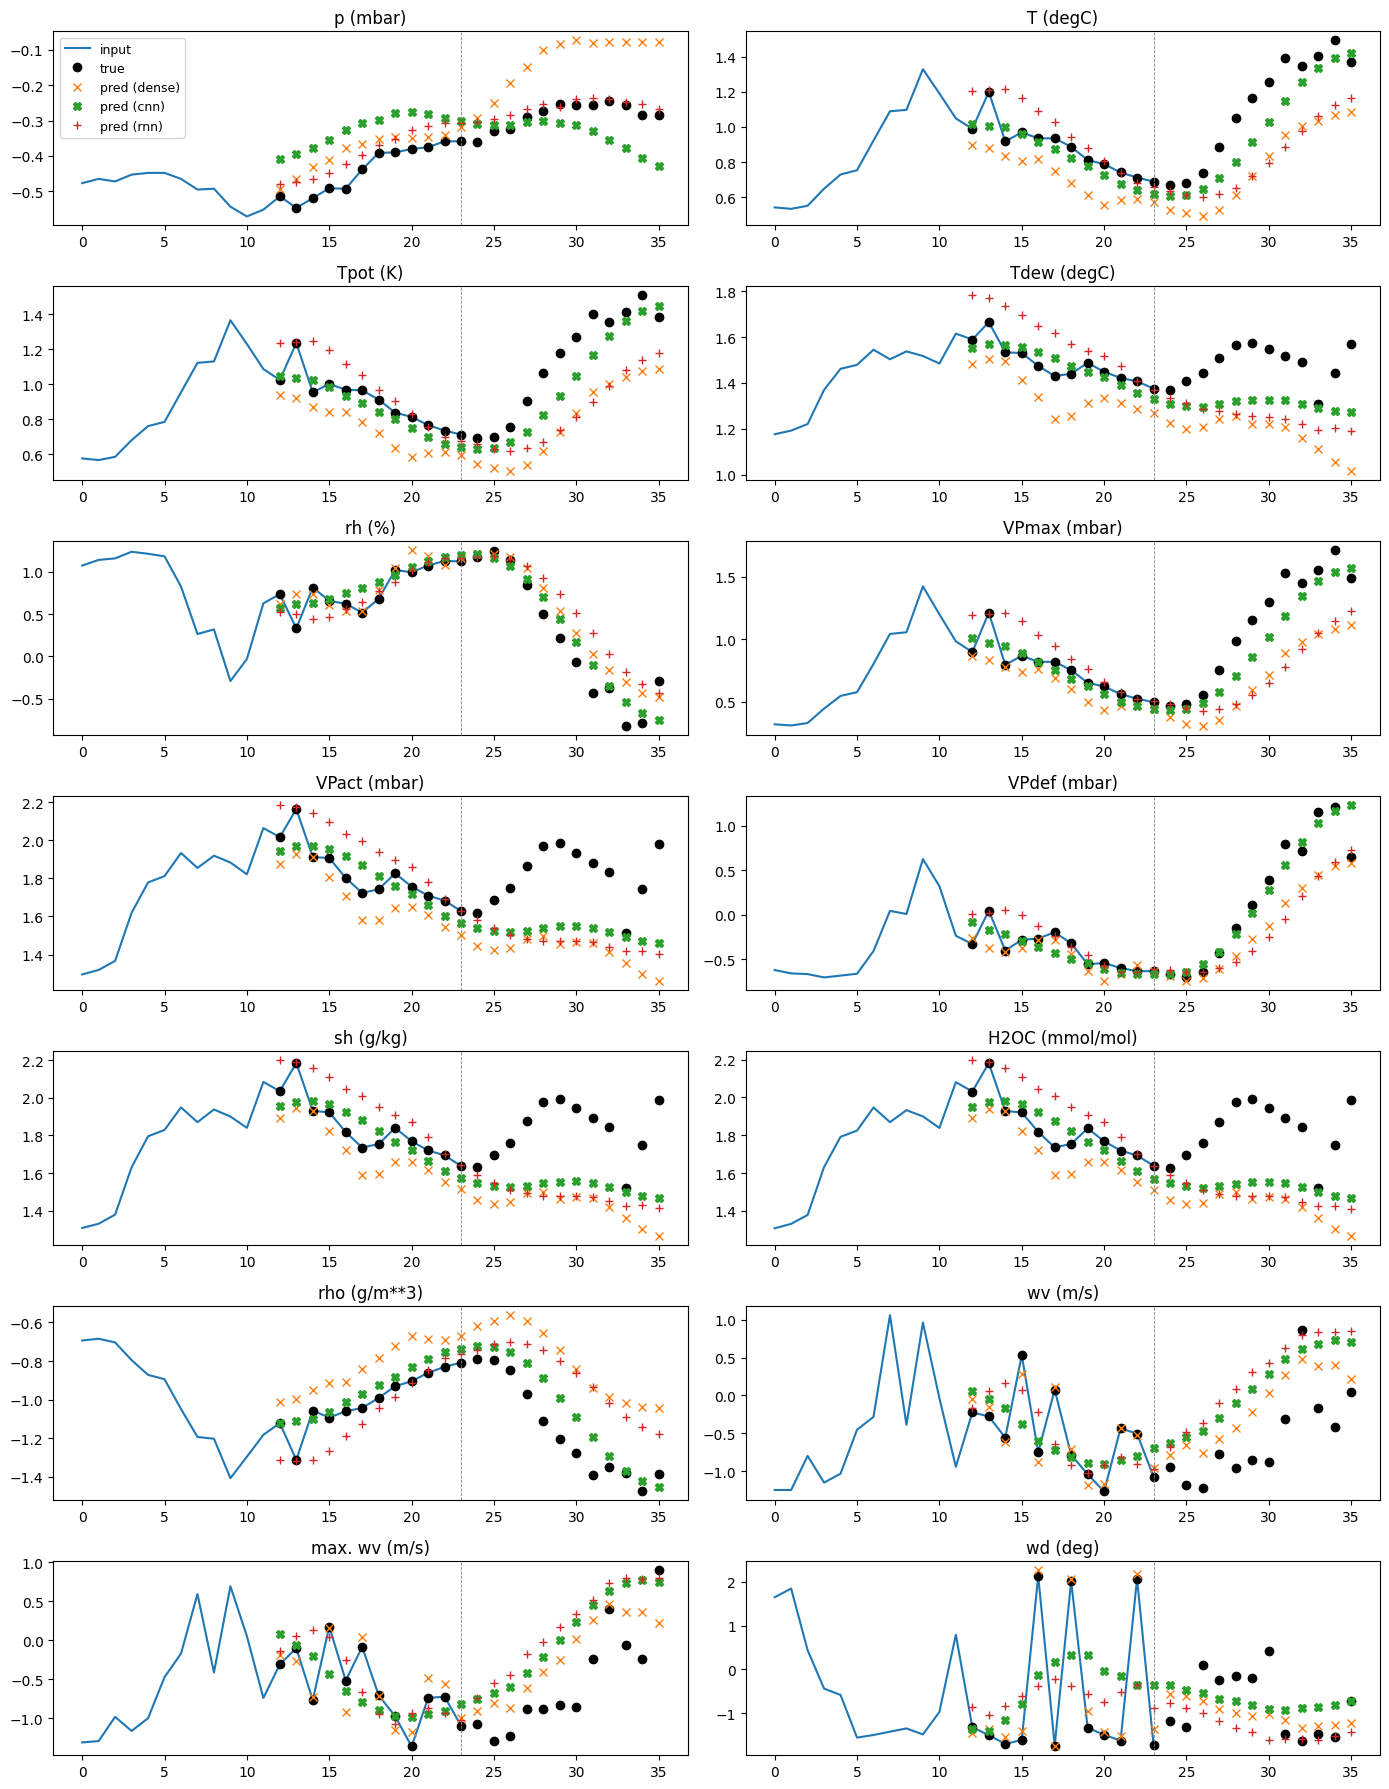

In [56]:
start_idx = 2000

plot_models_forecast_comparison(models, wg, start_idx)